# Notebook Base de Benchmarking entre Modelos

Este notebook compara **Kimi**, **Claude Opus**, **GPT-4o** e **Gemini** usando os mesmos prompts e métricas padronizadas.

Métricas coletadas:
- Tokens de entrada e saída
- Tempo de resposta
- Custo estimado
- Qualidade da resposta (avaliação manual ou automatizada)

## 1. Configuração do ambiente

In [2]:
# Instalação das dependências (execute uma vez)
!pip install openai anthropic google-generativeai python-dotenv pandas matplotlib

  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached protobuf-5.29.6-cp310-abi3-win_amd64.whl.metadata (592 bytes)
INFO: pip is looking at multiple versions of google-api-core to determine which version is compatible with other requirements. This could take a while.
  Using cached google_api_core-2.38.0-py3-none-any.whl.metadata (3.2 kB)
  Using cached google_api_core-2.37.0-py3-none-any.whl.metadata (3.2 kB)
  Using cached google_api_core-2.36.0-py3-none-any.whl.metadata (3.2 kB)
  Using cached google_api_core-2.34.0-py3-none-any.whl.metadata (2.9 kB)
  Using cached google_api_core-2.33.0-py3-none-any.whl.metadata (3.2 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
INFO: pip is looking at multiple versions of google-api-core[grpc] to determine which version is compatible with other requirements. This could take a while.
  Using cached grpcio_status-1.84.0-py3-none-any.whl.metadata (1.3 kB)
  Using cached pyasn1_modules-0.4.

In [4]:
pip install openai anthropic

  Using cached anthropic-1.11.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached docstring_parser-0.18.0-py3-none-any.whl.metadata (3.5 kB)
Using cached anthropic-1.11.0-py3-none-any.whl (1.7 MB)
Using cached docstring_parser-0.18.0-py3-none-any.whl (22 kB)

   -------------------- ------------------- 1/2 [anthropic]
   -------------------- ------------------- 1/2 [anthropic]
   -------------------- ------------------- 1/2 [anthropic]
   -------------------- ------------------- 1/2 [anthropic]
   -------------------- ------------------- 1/2 [anthropic]
   -------------------- ------------------- 1/2 [anthropic]
   -------------------- ------------------- 1/2 [anthropic]
   -------------------- ------------------- 1/2 [anthropic]
   -------------------- ------------------- 1/2 [anthropic]
   -------------------- ------------------- 1/2 [anthropic]
   -------------------- ------------------- 1/2 [anthropic]
   -------------------- ------------------- 1/2 [anthropic]
   -----------------

In [6]:
pip install google-generativeai

  Using cached google_generativeai-0.8.6-py3-none-any.whl.metadata (3.9 kB)
  Using cached google_ai_generativelanguage-0.6.15-py3-none-any.whl.metadata (5.7 kB)
  Using cached google_api_core-2.41.0-py3-none-any.whl.metadata (3.2 kB)
  Using cached google_api_python_client-2.201.0-py3-none-any.whl.metadata (6.8 kB)
  Using cached google_auth-2.60.0-py3-none-any.whl.metadata (6.0 kB)
  Using cached proto_plus-1.29.0-py3-none-any.whl.metadata (2.2 kB)
  Using cached protobuf-5.29.6-cp310-abi3-win_amd64.whl.metadata (592 bytes)
  Using cached googleapis_common_protos-1.75.5-py3-none-any.whl.metadata (8.5 kB)
INFO: pip is looking at multiple versions of google-api-core to determine which version is compatible with other requirements. This could take a while.
  Using cached google_api_core-2.40.0-py3-none-any.whl.metadata (3.2 kB)
  Using cached google_api_core-2.39.0-py3-none-any.whl.metadata (3.2 kB)
  Using cached google_api_core-2.38.0-py3-none-any.whl.metadata (3.2 kB)
  Using cached 

In [12]:
pip install groq

  Using cached groq-1.7.0-py3-none-any.whl.metadata (16 kB)
Using cached groq-1.7.0-py3-none-any.whl (143 kB)
Note: you may need to restart the kernel to use updated packages.


In [14]:
import os
import time
import json
import pandas as pd
from dotenv import load_dotenv
from groq import Groq


# Clientes
import openai
import anthropic
import google.generativeai as genai

load_dotenv()

# Credenciais
KIMI_API_KEY = os.getenv("KIMI_API_KEY")
ANTHROPIC_API_KEY = os.getenv("ANTHROPIC_API_KEY")
OPENAI_API_KEY = os.getenv("OPEN_API_KEY")
GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY")
GROQ_API_TOKEN = os.getenv("GROQ_API_TOKEN")

# Clientes configurados
kimi_client = openai.OpenAI(api_key=KIMI_API_KEY, base_url="https://api.moonshot.cn/v1")
anthropic_client = anthropic.Anthropic(api_key=ANTHROPIC_API_KEY)
openai_client = openai.OpenAI(api_key=OPENAI_API_KEY)
genai.configure(api_key=GOOGLE_API_KEY)
groq_client = Groq(api_key=GROQ_API_TOKEN)

## 2. Tabela de preços por 1M tokens

Atualize os valores conforme a tabela oficial de cada provider.

In [15]:
# Preços por 1M tokens (USD) — verificados em 2026-08-03.
# As chaves precisam bater com o campo "provider" retornado por cada call_*().
PRICES = {
    "kimi":        {"input":  3.00, "output": 15.00},  # kimi-k3 (Moonshot)
    "claude-opus": {"input":  4.00, "output": 20.00},  # claude-opus-5.5 (Anthropic)
    "gpt-5.5":     {"input":  5.00, "output": 30.00},  # gpt-5.5 (OpenAI), faixa <272K
    "gemini":      {"input":  0.75, "output":  3.75},  # gemini-3.7-flash (Google) - Preço promocional até 31/12/2026
    "groq":        {"input":  1.50, "output":  7.50},  # groq para openai/gpt-oss-20b
}

## 3. Função padronizada de chamada

Cada modelo recebe o mesmo `system_prompt` e `user_prompt`. A função retorna sempre a mesma estrutura de dados.

In [37]:
def call_kimi(system_prompt, user_prompt, model="kimi-k2.6"):
    start = time.time()
    response = kimi_client.chat.completions.create(
        model=model,
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt}
        ],
        temperature=1.0
    )
    elapsed = time.time() - start
    return {
        "provider": "kimi",
        "model": model,
        "response": response.choices[0].message.content,
        "input_tokens": response.usage.prompt_tokens,
        "output_tokens": response.usage.completion_tokens,
        "total_tokens": response.usage.total_tokens,
        "time_seconds": elapsed
    }

def call_groq(system_prompt, user_prompt, model="openai/gpt-oss-20b"):
    start = time.time()
    response = groq_client.chat.completions.create(
        model=model,
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt}
        ],
        temperature=1.0
    )
    elapsed = time.time() - start
    return {
        "provider": "groq",
        "model": model,
        "response": response.choices[0].message.content,
        "input_tokens": response.usage.prompt_tokens,
        "output_tokens": response.usage.completion_tokens,
        "total_tokens": response.usage.total_tokens,
        "time_seconds": elapsed
    }

def call_claude(system_prompt, user_prompt, model="claude-haiku-4-5-20251001"):
    start = time.time()
    # O claude-opus-5 não aceita temperature (400 invalid_request_error) e vem com
    # thinking ligado por padrão, que consome parte do max_tokens — por isso o
    # limite é mais folgado que os 4096 usados no opus-4-6.
    response = anthropic_client.messages.create(
        model=model,
        max_tokens=1000,
        system=system_prompt,
        messages=[{"role": "user", "content": user_prompt}]
    )
    elapsed = time.time() - start
    # Com thinking ligado, content[0] é um bloco 'thinking'; o texto vem depois.
    text = next(b.text for b in response.content if b.type == "text")
    return {
        "provider": "claude-opus",
        "model": model,
        "response": text,
        "input_tokens": response.usage.input_tokens,
        "output_tokens": response.usage.output_tokens,
        "total_tokens": response.usage.input_tokens + response.usage.output_tokens,
        "time_seconds": elapsed
    }

def call_openai(system_prompt, user_prompt, model="gpt-5.5"):
    start = time.time()
    # O gpt-5.5 aceita apenas o temperature padrão (1). Enviar 0.3 devolve
    # 400 unsupported_value, por isso o parâmetro é omitido aqui.
    response = openai_client.chat.completions.create(
        model=model,
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt}
        ]
    )
    elapsed = time.time() - start
    return {
        "provider": "gpt-5.5",
        "model": model,
        "response": response.choices[0].message.content,
        "input_tokens": response.usage.prompt_tokens,
        "output_tokens": response.usage.completion_tokens,
        "total_tokens": response.usage.total_tokens,
        "time_seconds": elapsed
    }

def call_gemini(system_prompt, user_prompt, model="gemini-3.5-flash-lite"):
    start = time.time()
    gemini_model = genai.GenerativeModel(model)
    response = gemini_model.generate_content(
        [system_prompt, user_prompt],
        generation_config={"temperature": 0.3}
    )
    elapsed = time.time() - start
    usage = response.usage_metadata
    # O preço de output do Gemini inclui os tokens de raciocínio, que NÃO entram
    # em candidates_token_count e não são expostos em campo próprio neste SDK.
    # (total - prompt) captura raciocínio + resposta, que é o que é cobrado.
    output_tokens = usage.total_token_count - usage.prompt_token_count
    return {
        "provider": "gemini",
        "model": model,
        "response": response.text,
        "input_tokens": usage.prompt_token_count,
        "output_tokens": output_tokens,
        "total_tokens": usage.total_token_count,
        "time_seconds": elapsed
    }

## 4. Função de cálculo de custo e execução do benchmark

In [38]:
def calculate_cost(provider, input_tokens, output_tokens):
    prices = PRICES.get(provider, {})
    input_cost = (input_tokens / 1_000_000) * prices.get("input", 0)
    output_cost = (output_tokens / 1_000_000) * prices.get("output", 0)
    return round(input_cost + output_cost, 6)

# Colunas usadas para exibir a tabela resumida (sem o texto completo da resposta)
SUMMARY_COLS = ["provider", "model", "input_tokens", "output_tokens",
                "total_tokens", "time_seconds", "cost_usd"]

def run_benchmark(system_prompt, user_prompt):
    results = []
    callers = [call_kimi, call_claude, call_openai, call_gemini, call_groq]
    
    for caller in callers:
        try:
            result = caller(system_prompt, user_prompt)
            result["cost_usd"] = calculate_cost(
                result["provider"],
                result["input_tokens"],
                result["output_tokens"]
            )
            results.append(result)
        except Exception as e:
            results.append({
                "provider": caller.__name__.replace("call_", ""),
                "model": "error",
                "response": str(e),
                "input_tokens": 0,
                "output_tokens": 0,
                "total_tokens": 0,
                "time_seconds": 0,
                "cost_usd": 0
            })
            print(e)
    
    # Mantém a coluna 'response': as células seguintes exibem e avaliam o texto.
    # Use df[SUMMARY_COLS] quando quiser só as métricas.
    return pd.DataFrame(results)[SUMMARY_COLS + ["response"]]

def display_responses(df):
    for _, row in df.iterrows():
        print(f"\n=== {row['provider'].upper()} | {row['model']} ===")
        print(f"Tokens: {row['total_tokens']} | Tempo: {row['time_seconds']:.2f}s | Custo: ${row['cost_usd']:.6f}")
        print("-" * 60)

## 5. Benchmark textual

In [39]:
system_prompt = "Você é um especialista em tecnologia. Responda de forma clara e objetiva."
user_prompt = "Explique o que é um LLM e cite três aplicações práticas em desenvolvimento de software."

df_text = run_benchmark(system_prompt, user_prompt)
df_text[SUMMARY_COLS]

,provider,model,input_tokens,output_tokens,total_tokens,time_seconds,cost_usd
0,kimi,kimi-k2.6,58,966,1024,17.672162,0.014664
1,claude-opus,claude-haiku-4-5-20251001,49,396,445,4.181425,0.010145
2,gpt-5.5,gpt-5.5,44,189,233,4.166824,0.005890
3,gemini,gemini-3.5-flash-lite,36,324,360,2.106242,0.002484
4,groq,openai/gpt-oss-20b,108,378,486,0.839769,0.000000


In [40]:
display_responses(df_text)

for _, row in df_text.iterrows():
    print(f"\n{row['provider'].upper()}:")
    print(row['response'][:500] + "..." if len(row['response']) > 500 else row['response'])


=== KIMI | kimi-k2.6 ===
Tokens: 1024 | Tempo: 17.67s | Custo: $0.014664
------------------------------------------------------------

=== CLAUDE-OPUS | claude-haiku-4-5-20251001 ===
Tokens: 445 | Tempo: 4.18s | Custo: $0.010145
------------------------------------------------------------

=== GPT-5.5 | gpt-5.5 ===
Tokens: 233 | Tempo: 4.17s | Custo: $0.005890
------------------------------------------------------------

=== GEMINI | gemini-3.5-flash-lite ===
Tokens: 360 | Tempo: 2.11s | Custo: $0.002484
------------------------------------------------------------

=== GROQ | openai/gpt-oss-20b ===
Tokens: 486 | Tempo: 0.84s | Custo: $0.000000
------------------------------------------------------------

KIMI:
**LLM** (Large Language Model, ou Grande Modelo de Linguagem) é um modelo de inteligência artificial baseado em redes neurais profundas — geralmente arquitetura *transformer* — treinado em enormes volumes de texto. Ele aprende padrões linguísticos e contextuais para prever a seq

## 6. Benchmark de geração de código

In [41]:
system_code = "Você é um desenvolvedor Python sênior. Retorne apenas o código, sem explicações."
user_code = """Escreva uma função Python chamada `is_prime(n)` que verifica se um número inteiro é primo.
Inclua também 3 testes unitários usando assert."""

df_code = run_benchmark(system_code, user_code)
df_code[SUMMARY_COLS]

,provider,model,input_tokens,output_tokens,total_tokens,time_seconds,cost_usd
0,kimi,kimi-k2.6,73,555,628,14.755487,0.008544
1,claude-opus,claude-haiku-4-5-20251001,72,229,301,2.585124,0.006085
2,gpt-5.5,gpt-5.5,62,163,225,10.109063,0.005200
3,gemini,gemini-3.5-flash-lite,55,146,201,115.500129,0.001178
4,groq,openai/gpt-oss-20b,126,523,649,2.152180,0.000000


In [42]:
import re

def extract_python_code(response):
    """Extrai blocos de código markdown da resposta."""
    match = re.search(r"```python\n(.*?)\n```", response, re.DOTALL)
    return match.group(1) if match else response

def evaluate_code(response):
    """Tenta executar o código gerado e verifica se passa nos asserts."""
    code = extract_python_code(response)
    try:
        exec(code, {})
        return "OK"
    except AssertionError:
        return "ASSERT_FAILED"
    except Exception as e:
        return f"ERROR: {e}"

df_code["execution_result"] = df_code["response"].apply(evaluate_code)
df_code[["provider", "cost_usd", "execution_result"]]

Todos os testes passaram!


,provider,cost_usd,execution_result
0,kimi,0.008544,OK
1,claude-opus,0.006085,OK
2,gpt-5.5,0.005200,OK
3,gemini,0.001178,OK
4,groq,0.000000,OK


## 7. Visualização comparativa

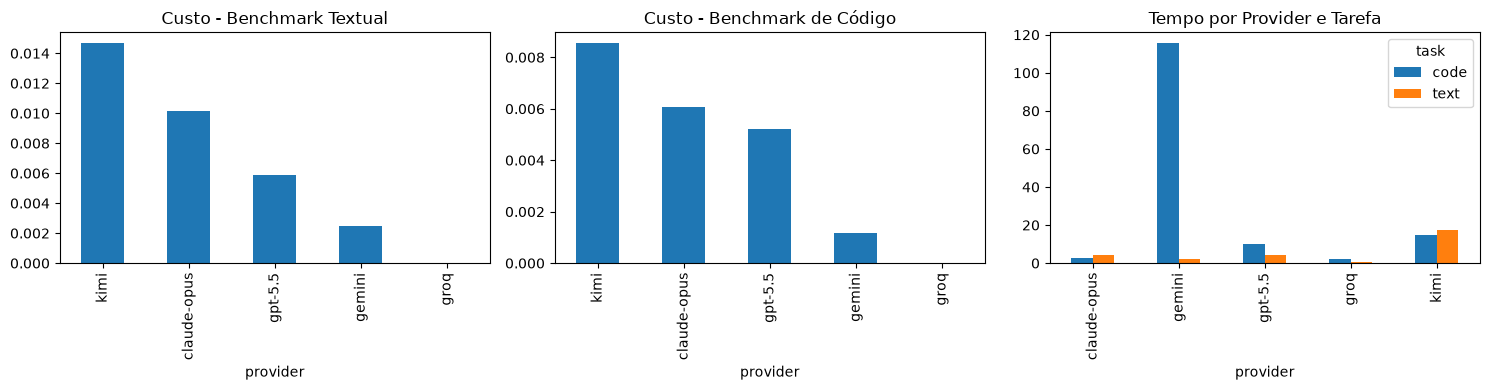

In [43]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df_text.plot.bar(x="provider", y="cost_usd", ax=axes[0], title="Custo - Benchmark Textual", legend=False)
df_code.plot.bar(x="provider", y="cost_usd", ax=axes[1], title="Custo - Benchmark de Código", legend=False)

combined = pd.concat([
    df_text.assign(task="text"),
    df_code.assign(task="code")
])
combined.pivot(index="provider", columns="task", values="time_seconds").plot.bar(ax=axes[2], title="Tempo por Provider e Tarefa")

plt.tight_layout()
plt.show()

## 8. Exportação dos resultados

In [44]:
# Salva os resultados em CSV para análise posterior
df_text.to_csv("benchmark_texto.csv", index=False)
df_code.to_csv("benchmark_codigo.csv", index=False)
print("Resultados salvos em CSV")

Resultados salvos em CSV


## 9. Arquivo `.env` de exemplo

Crie um arquivo `.env` na mesma pasta do notebook com:

```
KIMI_API_KEY=sk-xxxxx
ANTHROPIC_API_KEY=sk-ant-xxxxx
OPENAI_API_KEY=sk-xxxxx
GOOGLE_API_KEY=xxxxx
```